# Jour 5 — Interprétation métier et recommandations

Objectifs :
1. **Profilage** des 4 segments retenus (classification mixte Ward + K-means) : moyennes / modes par cluster, radar charts.
2. **Taux de souscription** par segment (la cible `y` n'intervient qu'ici, *a posteriori*).
3. **Une recommandation marketing concrète par segment.**

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import SEED, DATA_PROC, FIGURES, RESULTS, MODELS
from src.preprocessing import load_processed, load_raw
from src.segments import SEGMENTS, SEG_COLORS

sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
def save(fig, name): fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight", dpi=150)

d = load_processed()
clean, y = d["clean"].copy(), d["y"]
raw = load_raw().drop_duplicates().reset_index(drop=True)      # mêmes lignes que `clean`
labels = np.load(DATA_PROC / "labels_final.npy")
clean["segment"] = labels
clean["campaign"] = raw["campaign"]
names = {k: f"S{k+1} · {v['nom']}" for k, v in SEGMENTS.items()}
clean["segment_nom"] = clean["segment"].map(names)
print(clean["segment_nom"].value_counts().sort_index())

segment_nom
S1 · Masse froide (fixe, taux élevés)    26939
S2 · Jeunes actifs mobiles (taux bas)     7015
S3 · Seniors et retraités épargnants      2541
S4 · Clients déjà sollicités              4681
Name: count, dtype: int64


## 1. Profils : moyennes (numériques) et modes / fréquences (qualitatives)

In [2]:
num_cols = ["age", "campaign", "previous", "euribor3m", "cons.conf.idx", "education_level"]
bin_cols = ["housing", "loan", "default_flag", "contact_cellular"]
g = clean.groupby("segment_nom")
profil = pd.concat([
    g.size().rename("effectif"),
    (100 * g.size() / len(clean)).rename("% clients"),
    g[num_cols].mean(),
    (100 * g[bin_cols].mean()).add_suffix(" (%)"),
    g[["job", "marital", "poutcome"]].agg(lambda s: s.mode()[0]).add_suffix(" (mode)"),
    (100 * y.groupby(clean["segment_nom"]).mean()).rename("taux souscription (%)"),
], axis=1)
glob = pd.Series({"effectif": len(clean), "% clients": 100, **clean[num_cols].mean().to_dict(),
                  **(100 * clean[bin_cols].mean()).add_suffix(" (%)").to_dict(),
                  "job (mode)": clean["job"].mode()[0], "marital (mode)": clean["marital"].mode()[0],
                  "poutcome (mode)": clean["poutcome"].mode()[0], "taux souscription (%)": 100 * y.mean()},
                 name="Ensemble")
profil = pd.concat([profil, glob.to_frame().T])
profil.to_csv(RESULTS / "j5_profils.csv")
profil.T

,"S1 · Masse froide (fixe, taux élevés)",S2 · Jeunes actifs mobiles (taux bas),S3 · Seniors et retraités épargnants,S4 · Clients déjà sollicités,Ensemble
effectif,26939,7015,2541,4681,41176
% clients,65.424033,17.036623,6.171071,11.368273,100
age,40.169902,37.718888,46.969303,38.866909,40.0238
campaign,2.825495,2.230791,1.816608,1.998291,2.567879
previous,0.0,0.0,0.413223,1.297586,0.173013
euribor3m,4.836677,1.304159,0.790971,1.635678,3.621293
cons.conf.idx,-39.390772,-45.852944,-31.532349,-43.754711,-40.502863
education_level,4.130406,4.156949,4.418339,4.260842,4.167525
housing (%),52.711682,59.686386,57.418339,58.000427,54.791626
loan (%),15.13048,15.851746,13.577332,15.274514,15.173888


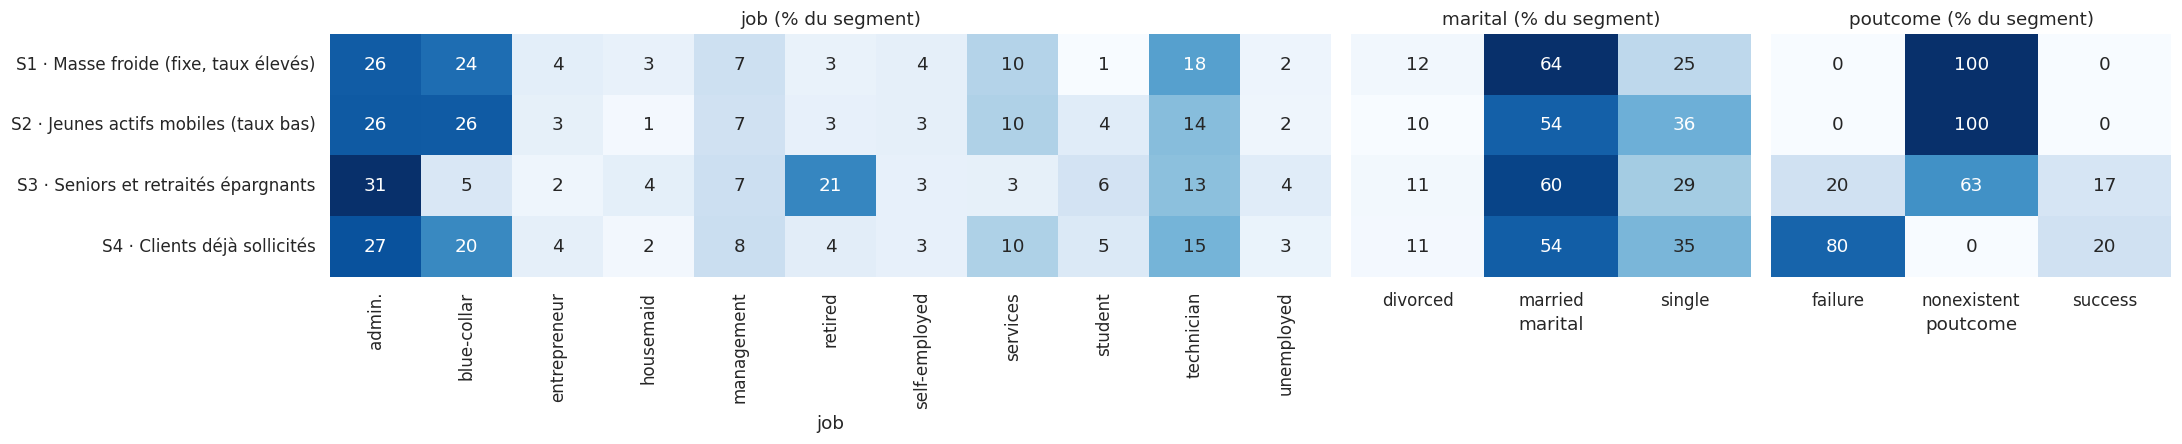

In [3]:
def crosstab_pct(col):
    return (100 * pd.crosstab(clean["segment_nom"], clean[col], normalize="index")).round(1)
fig, axes = plt.subplots(1, 3, figsize=(20, 4.2), gridspec_kw={"width_ratios": [3, 1.2, 1.2]})
for ax, col in zip(axes, ["job", "marital", "poutcome"]):
    sns.heatmap(crosstab_pct(col), annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"{col} (% du segment)"); ax.set_ylabel("")
axes[0].set_yticklabels(axes[0].get_yticklabels(), rotation=0)
for ax in axes[1:]: ax.set_yticklabels([])
fig.tight_layout(); save(fig, "j5_heatmaps_qualitatives")

## 2. Radar charts
Chaque axe est la moyenne du segment ramenée entre 0 (segment le plus bas) et 1 (le plus haut) pour comparer les profils.

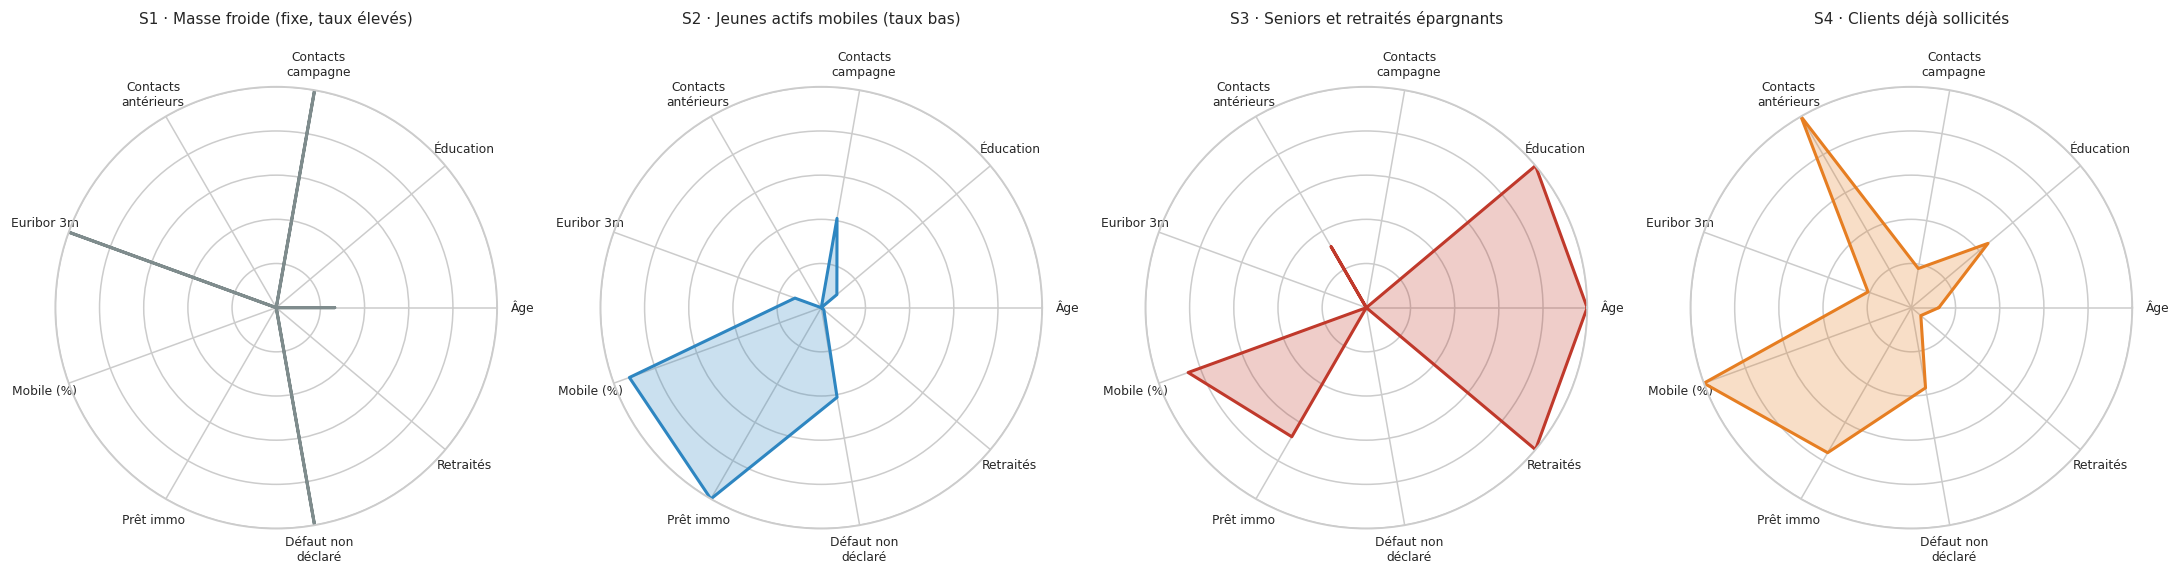

In [4]:
radar_vars = {"Âge": "age", "Éducation": "education_level", "Contacts\ncampagne": "campaign",
              "Contacts\nantérieurs": "previous", "Euribor 3m": "euribor3m", "Mobile (%)": "contact_cellular",
              "Prêt immo": "housing", "Défaut non\ndéclaré": "default_flag", "Retraités": None}
M = clean.groupby("segment")[[v for v in radar_vars.values() if v]].mean()
M["retired"] = clean.assign(r=(clean["job"] == "retired")).groupby("segment")["r"].mean()
Mn = (M - M.min()) / (M.max() - M.min())
labels_ax = list(radar_vars.keys()); n = len(labels_ax)
angles = np.linspace(0, 2 * np.pi, n, endpoint=False).tolist(); angles += angles[:1]
fig, axes = plt.subplots(1, 4, figsize=(20, 5.2), subplot_kw={"polar": True})
for ax, (seg, row) in zip(axes, Mn.iterrows()):
    vals = row.tolist() + row.tolist()[:1]
    ax.plot(angles, vals, color=SEG_COLORS[seg], lw=2); ax.fill(angles, vals, color=SEG_COLORS[seg], alpha=.25)
    ax.set_xticks(angles[:-1]); ax.set_xticklabels(labels_ax, fontsize=8); ax.set_yticklabels([])
    ax.set_ylim(0, 1); ax.set_title(names[seg], fontsize=10, pad=18)
fig.tight_layout(); save(fig, "j5_radars")

**Lecture des profils et radars**
- **S1 Masse froide** : aucun historique, joints pour moitié sur ligne fixe, période de taux élevés, plus forte part de « défaut non déclaré » et plus forte pression d'appel.
- **S2 Jeunes actifs mobiles** : même absence d'historique, mais plus jeunes, plus de célibataires, contactés sur mobile en période de taux bas.
- **S3 Seniors épargnants** : le profil le plus âgé, sur-représentation des retraités (21 %), quasi aucun défaut non déclaré, meilleure confiance des ménages et une partie déjà convertie par le passé.
- **S4 Déjà sollicités** : défini par l'historique de campagne (`previous` ≥ 1 pour tous, `poutcome` = failure/success).

Le métier modal est `admin.` partout (premier métier de la base) : ce sont les **écarts de répartition** (heatmap) qui différencient les segments — retraités et étudiants dans S3, ouvriers (`blue-collar`) dans S1/S2.

## 3. Taux de souscription par segment

,taux,souscripteurs,clients,lift,part des souscripteurs (%)
segment,,,,,
"S1 · Masse froide (fixe, taux élevés)",0.049,1311,26939,0.432,28.260
S2 · Jeunes actifs mobiles (taux bas),0.173,1217,7015,1.540,26.234
S3 · Seniors et retraités épargnants,0.425,1080,2541,3.773,23.281
S4 · Clients déjà sollicités,0.220,1031,4681,1.955,22.225


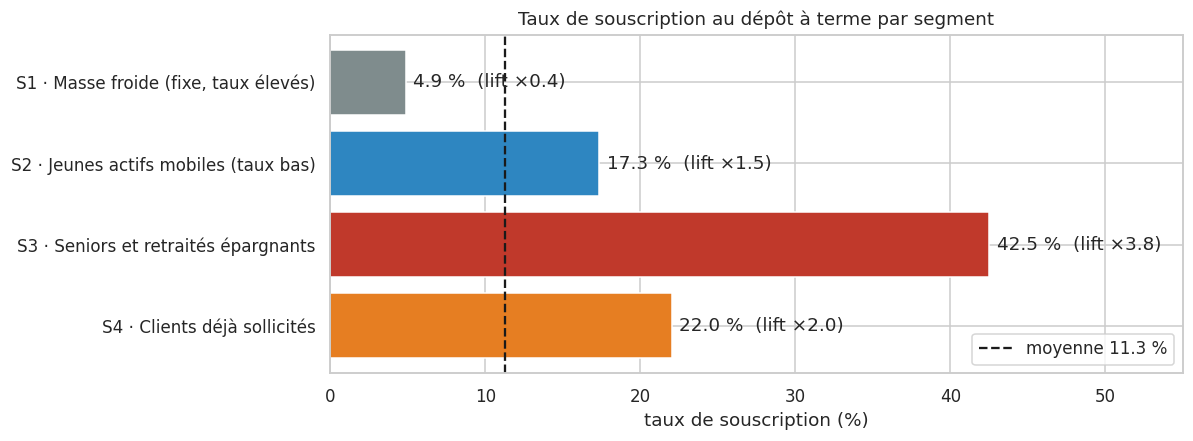

In [5]:
rate = y.groupby(clean["segment"]).agg(["mean", "sum", "size"])
rate["lift"] = rate["mean"] / y.mean()
rate["part des souscripteurs (%)"] = 100 * rate["sum"] / y.sum()
rate.index = rate.index.map(names)
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(rate.index, 100 * rate["mean"], color=[SEG_COLORS[k] for k in range(4)])
ax.axvline(100 * y.mean(), ls="--", color="k", label=f"moyenne {100*y.mean():.1f} %")
for b, v, l in zip(bars, rate["mean"], rate["lift"]):
    ax.text(b.get_width() + .5, b.get_y() + b.get_height() / 2, f"{100*v:.1f} %  (lift ×{l:.1f})", va="center")
ax.set_xlabel("taux de souscription (%)"); ax.invert_yaxis(); ax.legend(loc="lower right"); ax.set_xlim(0, 55)
ax.set_title("Taux de souscription au dépôt à terme par segment"); save(fig, "j5_taux_souscription")
rate.rename(columns={"mean": "taux", "sum": "souscripteurs", "size": "clients"}).round(3)

## 4. Lecture temporelle (post hoc)
Le fichier est ordonné chronologiquement (mai 2008 → novembre 2010). Les variables `month` et `day_of_week`, exclues de la segmentation, permettent de vérifier **a posteriori** si certains segments sont liés à la conjoncture.

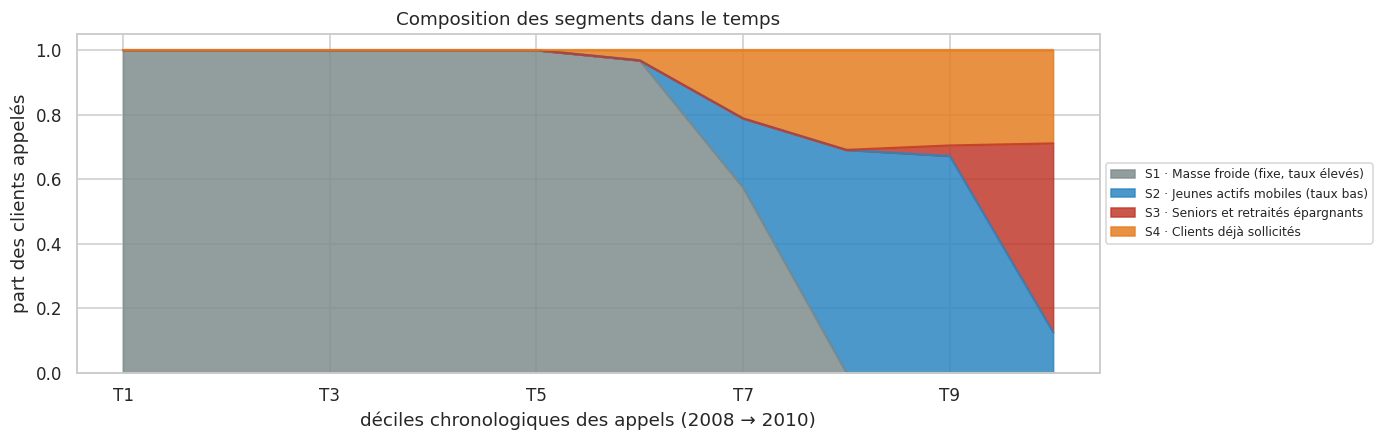

In [6]:
clean["periode"] = pd.cut(np.arange(len(clean)), 10, labels=[f"T{i+1}" for i in range(10)])
tp = pd.crosstab(clean["periode"], clean["segment_nom"], normalize="index")
fig, ax = plt.subplots(figsize=(12, 4))
tp.plot.area(ax=ax, color=[SEG_COLORS[k] for k in range(4)], alpha=.85)
ax.set_ylabel("part des clients appelés"); ax.set_xlabel("déciles chronologiques des appels (2008 → 2010)")
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1, .5)); ax.set_title("Composition des segments dans le temps")
save(fig, "j5_segments_temps")

**Lecture.** L'effet de période est **massif** : S1 regroupe la quasi-totalité des appels des six premiers déciles (2008, taux élevés) puis disparaît à partir du 8ᵉ décile ; S4 et S2 apparaissent avec la baisse des taux (fin 2008-2009) et S3 n'émerge qu'en toute fin de période (2010, taux au plancher). Une partie de la segmentation reflète donc le **contexte de l'appel** (via `euribor3m`) autant que le client. C'est assumé : pour une banque, savoir *quand* un profil est réceptif est actionnable. Mais cela impose une **mise à jour régulière** des centres et une variante « profil pur » (sans indicateurs macro) pourrait être testée — cf. bonus sélection de variables.

**Message clé** : les segments S2+S3+S4 (35 % des clients) concentrent **72 % des souscripteurs**. Concentrer les appels conseillers sur eux et traiter S1 par des canaux à faible coût permettrait de réduire fortement le nombre d'appels pour un volume de souscriptions comparable.

## 5. Fiches segments et recommandations marketing

In [7]:
for k, s in SEGMENTS.items():
    r = rate.iloc[k]
    print(f"■ {names[k]}  —  {int(r['size']):,} clients ({100*r['size']/len(clean):.1f} %), "
          f"souscription {100*r['mean']:.1f} % (lift ×{r['lift']:.2f})")
    print(f"  Profil : {s['profil']}")
    print(f"  Recommandation : {s['reco']}\n")

■ S1 · Masse froide (fixe, taux élevés)  —  26,939 clients (65.4 %), souscription 4.9 % (lift ×0.43)
  Profil : 65 % des clients ; jamais contactés auparavant ; appelés en période de taux élevés (Euribor ≈ 4,8 %) ; 51 % joints sur ligne fixe ; 26 % n'ont pas déclaré leur situation de défaut ; pression d'appel la plus forte (2,8 appels en moyenne).
  Recommandation : Réduire la pression téléphonique : plafonner à 2 appels, basculer sur des canaux à faible coût (SMS, e-mail, application) et ne déclencher l'appel conseiller qu'après un signal d'intérêt (clic, simulation). Compléter les données manquantes (défaut, mobile) avant toute relance.

■ S2 · Jeunes actifs mobiles (taux bas)  —  7,015 clients (17.0 %), souscription 17.3 % (lift ×1.54)
  Profil : 17 % des clients ; 38 ans en moyenne, 36 % de célibataires ; jamais contactés ; joignables sur mobile (90 %) ; appelés en période de taux bas (Euribor ≈ 1,3 %) et de forte inquiétude des ménages (confiance −46).
  Recommandation : Campagne 

In [8]:
fiche = pd.DataFrame([{"segment": names[k], "clients": int(rate.iloc[k]["size"]),
                       "taux_souscription_%": round(100 * rate.iloc[k]["mean"], 1),
                       "lift": round(rate.iloc[k]["lift"], 2), "profil": s["profil"], "recommandation": s["reco"]}
                      for k, s in SEGMENTS.items()])
fiche.to_csv(RESULTS / "j5_fiches_segments.csv", index=False)
print("Fiches sauvegardées.")

Fiches sauvegardées.
